# Experiment 10 — CIFAR-10 CNN: Airplane vs. Automobile

The interactive companion to
`experiments/10_cifar10_cnn_airplane_vs_automobile/train.py`.

**Goal:** experiment 06 asked "is this an airplane?" across all of
CIFAR-10 -- a task where a do-nothing model scores ~90% accuracy. This
experiment filters the dataset down to ONLY airplane and automobile images,
a perfectly balanced 5,000/5,000 split. Airplane and automobile were picked
deliberately: both are rigid man-made objects usually photographed against
a clean background -- a plausibly *easier*, and genuinely balanced, pair.

Uses `cifar10_data.CIFAR10HF` (see experiment 06) rather than
`torchvision.datasets.CIFAR10` directly -- same reasoning as there.

In [1]:
import sys
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import transforms
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent
EXP06_DIR = REPO_ROOT / "experiments" / "06_cifar10_cnn_airplane"
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
if str(EXP06_DIR) not in sys.path:
    sys.path.insert(0, str(EXP06_DIR))

from cifar10_data import CIFAR10HF, CLASS_NAMES
from utils import get_device, set_seed

# Override the Agg backend that utils.plotting sets, so plots render inline here.
%matplotlib inline

set_seed(42)
device = get_device()
print(f"device: {device}")

POS_CLASS = 0  # airplane
NEG_CLASS = 1  # automobile
DATA_ROOT = REPO_ROOT / "data" / "raw"

device: cpu


## Data

CIFAR-10 filtered to only airplane and automobile -- a genuinely balanced
binary task, unlike experiment 06's airplane-vs-everything.

In [2]:
def filter_to_two_classes(dataset):
    targets = torch.as_tensor(dataset.targets)
    mask = (targets == POS_CLASS) | (targets == NEG_CLASS)
    indices = mask.nonzero().squeeze(1).tolist()
    return Subset(dataset, indices)


transform = transforms.ToTensor()
train_all = CIFAR10HF(DATA_ROOT, train=True, download=True, transform=transform)
test_all = CIFAR10HF(DATA_ROOT, train=False, download=True, transform=transform)

train_full = filter_to_two_classes(train_all)
test_set = filter_to_two_classes(test_all)

val_size = 1000
n_train = len(train_full) - val_size
generator = torch.Generator().manual_seed(42)
train_set, val_set = random_split(train_full, [n_train, val_size], generator=generator)

batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)

print(f"train: {len(train_set)}  val: {len(val_set)}  test: {len(test_set)}")

test_targets = torch.as_tensor(test_all.targets)[test_set.indices]
majority_baseline = max(
    (test_targets == POS_CLASS).float().mean().item(),
    (test_targets == NEG_CLASS).float().mean().item(),
)
print(f"majority-class baseline: {majority_baseline:.4f}  (vs. experiment 06's ~0.90)")

train: 9000  val: 1000  test: 2000
majority-class baseline: 0.5000  (vs. experiment 06's ~0.90)


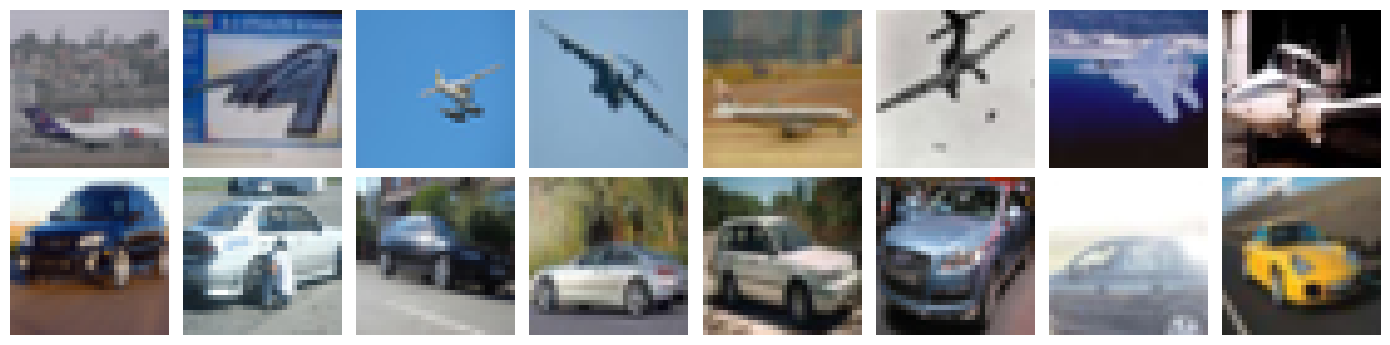

In [3]:
# A peek at the two classes
fig, axes = plt.subplots(2, 8, figsize=(14, 3.6))
shown = {POS_CLASS: 0, NEG_CLASS: 0}
i = 0
while min(shown.values()) < 8:
    img, label = train_full[i]
    if shown[label] < 8:
        row = 0 if label == POS_CLASS else 1
        axes[row, shown[label]].imshow(img.permute(1, 2, 0))
        axes[row, shown[label]].axis("off")
        shown[label] += 1
    i += 1
fig.tight_layout()
plt.show()

## Model

Identical architecture to experiment 06 -- this experiment is about the
*data*, not the model.

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


model = CNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"model: CNN, {n_params} parameters")

model: CNN, 89249 parameters


## Training loop

In [5]:
def binary_labels(y):
    return (y == POS_CLASS).float()


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, n = 0.0, 0
    tp = fp = fn = tn = 0
    for x, y in loader:
        x = x.to(device)
        target = binary_labels(y).to(device)
        logits = model(x)
        total_loss += loss_fn(logits, target).item() * x.size(0)
        n += x.size(0)
        pred = (logits > 0).float()
        tp += ((pred == 1) & (target == 1)).sum().item()
        fp += ((pred == 1) & (target == 0)).sum().item()
        fn += ((pred == 0) & (target == 1)).sum().item()
        tn += ((pred == 0) & (target == 0)).sum().item()
    return {
        "loss": total_loss / n,
        "accuracy": (tp + tn) / n,
        "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
    }


loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 12
train_losses, val_losses, val_accuracies = [], [], []

for epoch in range(1, epochs + 1):
    model.train()
    running_loss, n_seen = 0.0, 0
    for x, y in train_loader:
        x = x.to(device)
        target = binary_labels(y).to(device)

        logits = model(x)
        loss = loss_fn(logits, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)
        n_seen += x.size(0)

    train_loss = running_loss / n_seen
    val_metrics = evaluate(model, val_loader, loss_fn)

    train_losses.append(train_loss)
    val_losses.append(val_metrics["loss"])
    val_accuracies.append(val_metrics["accuracy"])

    print(
        f"epoch {epoch:2d} | train loss {train_loss:.4f} | val loss {val_metrics['loss']:.4f} "
        f"| val acc {val_metrics['accuracy']:.4f} | val precision {val_metrics['precision']:.4f} "
        f"| val recall {val_metrics['recall']:.4f}"
    )

epoch  1 | train loss 0.5057 | val loss 0.4345 | val acc 0.7960 | val precision 0.9477 | val recall 0.6367


epoch  2 | train loss 0.3711 | val loss 0.3183 | val acc 0.8620 | val precision 0.8596 | val recall 0.8730


epoch  3 | train loss 0.3107 | val loss 0.2967 | val acc 0.8650 | val precision 0.8278 | val recall 0.9297


epoch  4 | train loss 0.2668 | val loss 0.2470 | val acc 0.8980 | val precision 0.8661 | val recall 0.9473


epoch  5 | train loss 0.2297 | val loss 0.2436 | val acc 0.8980 | val precision 0.9659 | val recall 0.8301


...

epoch  8 | train loss 0.1596 | val loss 0.1550 | val acc 0.9420 | val precision 0.9595 | val recall 0.9258


epoch  9 | train loss 0.1319 | val loss 0.1477 | val acc 0.9380 | val precision 0.9136 | val recall 0.9707


epoch 10 | train loss 0.1221 | val loss 0.1366 | val acc 0.9450 | val precision 0.9579 | val recall 0.9336


epoch 11 | train loss 0.1115 | val loss 0.1428 | val acc 0.9420 | val precision 0.9399 | val recall 0.9473


epoch 12 | train loss 0.1042 | val loss 0.1250 | val acc 0.9530 | val precision 0.9604 | val recall 0.9473


## Results

In [6]:
test_metrics = evaluate(model, test_loader, loss_fn)
print(f"test accuracy:  {test_metrics['accuracy']:.4f}  (majority-class baseline: {majority_baseline:.4f})")
print(f"test precision: {test_metrics['precision']:.4f}")
print(f"test recall:    {test_metrics['recall']:.4f}")

test accuracy:  0.9525  (majority-class baseline: 0.5000)
test precision: 0.9622
test recall:    0.9420


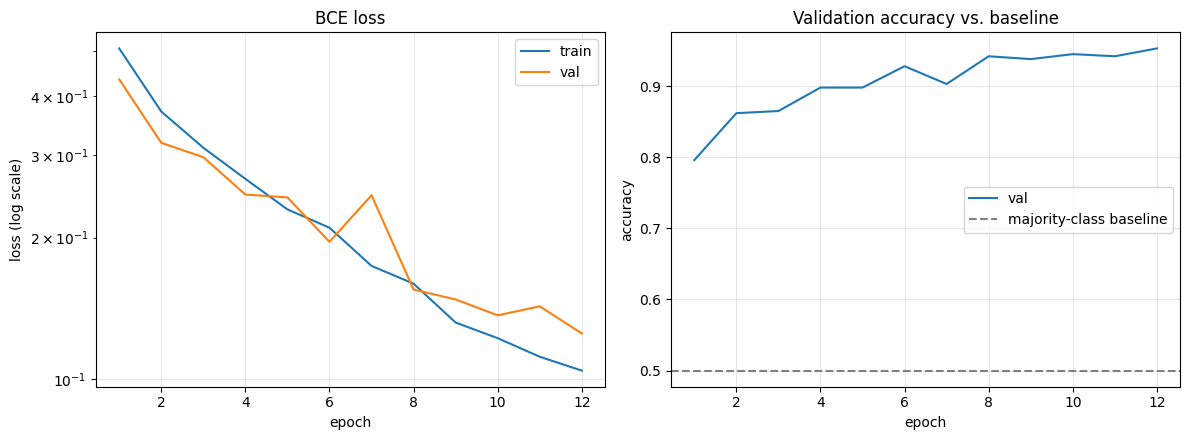

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(range(1, epochs + 1), train_losses, label="train")
axes[0].plot(range(1, epochs + 1), val_losses, label="val")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (log scale)")
axes[0].set_title("BCE loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, epochs + 1), val_accuracies, label="val")
axes[1].axhline(majority_baseline, color="gray", linestyle="--", label="majority-class baseline")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Validation accuracy vs. baseline"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

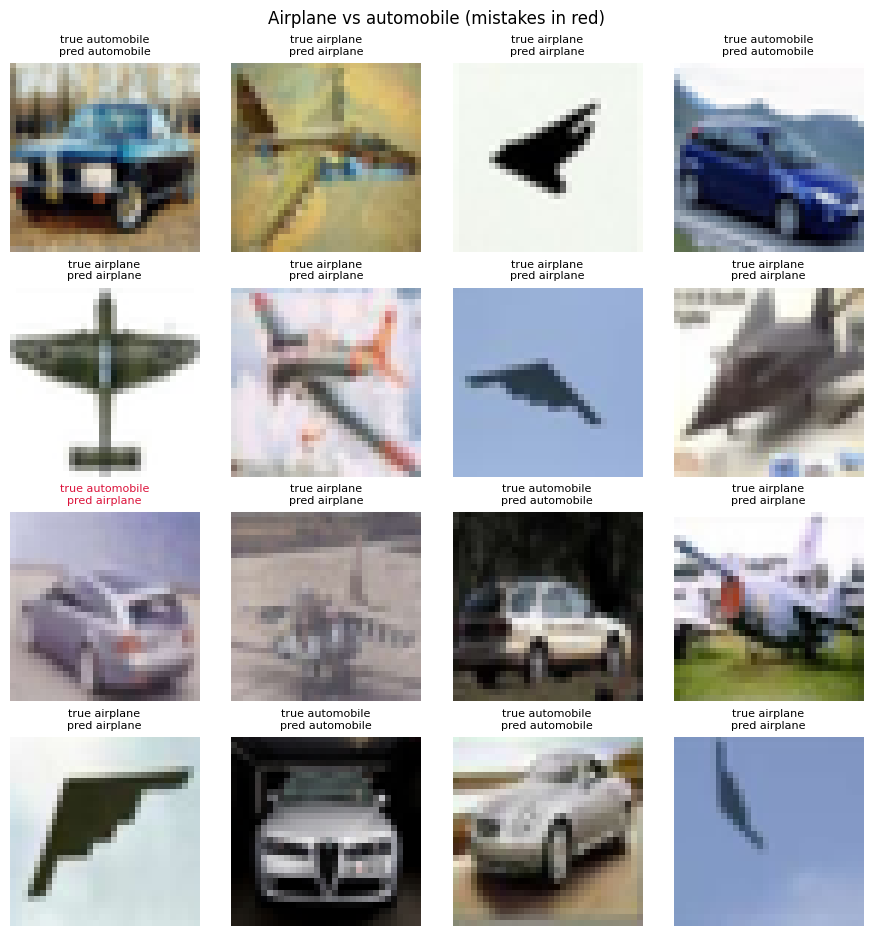

In [8]:
# Sample test predictions, mistakes highlighted in red
model.eval()
x_sample, y_sample = next(iter(DataLoader(test_set, batch_size=64, shuffle=True)))
with torch.no_grad():
    logits = model(x_sample.to(device))
    preds = (logits > 0).cpu().long()
true_is_airplane = (y_sample == POS_CLASS).long()

fig, axes = plt.subplots(4, 4, figsize=(9, 9.5))
for i, ax in enumerate(axes.flat):
    correct = preds[i] == true_is_airplane[i]
    ax.imshow(x_sample[i].permute(1, 2, 0))
    ax.set_title(
        f"true {'airplane' if true_is_airplane[i] else 'automobile'}\npred {'airplane' if preds[i] else 'automobile'}",
        fontsize=8, color="black" if correct else "crimson",
    )
    ax.axis("off")
fig.suptitle("Airplane vs automobile (mistakes in red)")
fig.tight_layout()
plt.show()

## Takeaways

- A bigger jump than experiment 08's MNIST case: accuracy only improves
  modestly (94.9% -> 95.3%) but recall jumps from 0.57 to 0.94 -- removing
  the visually-confusing negatives (birds, ships) that experiment 06's
  airplane-vs-rest task included is doing real work here, not just the
  balanced ratio itself.
- Unlike experiment 08 (MNIST), precision and recall stay meaningfully
  informative here even in the balanced setting -- CIFAR-10 photographs
  are noisy enough to leave real trade-offs visible.
- This CNN is the frozen teacher for experiment 11, which repeats
  experiment 07's function-distillation study against it.

See `experiments/10_cifar10_cnn_airplane_vs_automobile/README.md` for the
full writeup.